In [1]:
import pandas as pd

# Load the CSV file into a DataFrame
df = pd.read_csv("/home/mayank-sakat/.cache/kagglehub/datasets/amineipad/e-commerce-marketing-and-sales-revenue-prediction/versions/1/train.csv")
print(df.head())
print("\nDataFrame Info:")
print(df.info())

   id                 date region       channel product_category  \
0   1  2011-12-05 11:31:00   Nort        Search          General   
1   2  2011-04-27 14:01:00  North  Social Media          General   
2   3  2010-11-09 15:20:00  North     Affiliate          General   
3   4  2010-10-03 15:24:00  North     Affiliate          Storage   
4   5  2011-10-14 09:28:00  North        Search         Lighting   

  customer_segment  ad_spend  price  discount_rate  market_reach  impressions  \
0         Standard      9.00   0.75         0.2782          32.0          817   
1          Premium      3.35   3.35         0.0912          61.0         2289   
2           Budget      2.55   2.55         0.1997         461.0        14697   
3          Premium      2.95   2.95         0.4767         744.0        17578   
4          Premium     15.00   1.25         0.3536         226.0         6280   

   click_through_rate  competition_index  seasonality_index  \
0              0.0010               3.34 

In [2]:
# 1. Define the exact columns we need (Inputs + The Answer)
columns_to_keep = [
    'ad_spend', 
    'price', 
    'discount_rate', 
    'campaign_duration_days', 
    'sales_revenue'
]

# 2. Slice the dataframe to only keep those columns
df_clean = df[columns_to_keep].copy()

# 3. Drop any rows that have missing (NaN) values
df_clean = df_clean.dropna()

# 4. Prove the data is clean and ready for math
print(df_clean.info())

<class 'pandas.DataFrame'>
Index: 15226 entries, 0 to 17999
Data columns (total 5 columns):
 #   Column                  Non-Null Count  Dtype  
---  ------                  --------------  -----  
 0   ad_spend                15226 non-null  float64
 1   price                   15226 non-null  float64
 2   discount_rate           15226 non-null  float64
 3   campaign_duration_days  15226 non-null  float64
 4   sales_revenue           15226 non-null  float64
dtypes: float64(5)
memory usage: 713.7 KB
None


In [3]:
from sklearn.linear_model import LinearRegression
import joblib
import os

print("1. Isolating Inputs (X) and Target (y)...")
# X contains our 4 input features
X = df_clean[['ad_spend', 'price', 'discount_rate', 'campaign_duration_days']]
# y is the answer we want to predict
y = df_clean['sales_revenue']

print("2. Training the Multi-Variable Model...")
model = LinearRegression()
model.fit(X, y)

print("--- The Learned Mathematics ---")
# Zip binds the column names to their calculated weights (the 'm' multipliers)
for feature, weight in zip(X.columns, model.coef_):
    print(f"Weight for {feature}: {weight:.4f}")
print(f"Baseline (b): {model.intercept_:.4f}\n")

print("3. Freezing the Model for Production...")
# Since your notebook is in the 'notebooks/' folder, we navigate up one level ('../')
# to save it directly into your backend API folder.
save_path = "../app/ml/models/sales_model.joblib"

# Ensure the directory exists just in case
os.makedirs(os.path.dirname(save_path), exist_ok=True)

# Save the model
joblib.dump(model, save_path)
print(f"✅ Production model successfully saved to: {save_path}")

1. Isolating Inputs (X) and Target (y)...
2. Training the Multi-Variable Model...
--- The Learned Mathematics ---
Weight for ad_spend: 0.0125
Weight for price: -0.4901
Weight for discount_rate: -52.1141
Weight for campaign_duration_days: 0.2041
Baseline (b): 143.8543

3. Freezing the Model for Production...
✅ Production model successfully saved to: ../app/ml/models/sales_model.joblib


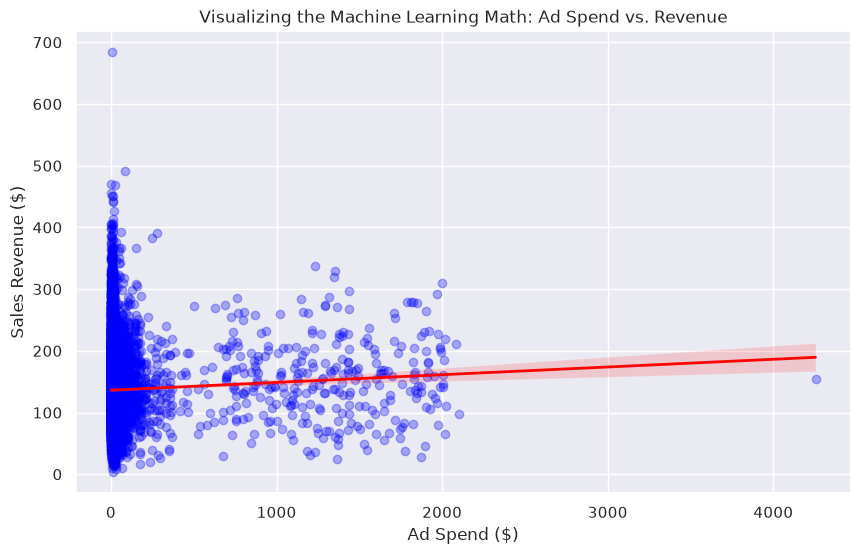

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Set the visual style
sns.set_theme(style="darkgrid")

plt.figure(figsize=(10, 6))
# regplot draws the scatter plot of data points AND the calculated regression line
sns.regplot(
    x=df_clean['ad_spend'], 
    y=df_clean['sales_revenue'], 
    scatter_kws={'alpha': 0.3, 'color': 'blue'}, 
    line_kws={'color': 'red', 'linewidth': 2}
)

plt.title("Visualizing the Machine Learning Math: Ad Spend vs. Revenue")
plt.xlabel("Ad Spend ($)")
plt.ylabel("Sales Revenue ($)")
plt.show()